# Analiza sentymentu komentarzy o kryptowalutach – dostrajanie CryptoBERT

Notebook korzysta z funkcji w `src/` – tych samych, które uruchamia potok DVC (`dvc repro`), CI i Jenkins.
Parametry są w `params.yaml`, przebiegi trafiają do MLflow na DagsHub (konfiguracja w pliku `.env`).

In [1]:
import os
import sys
from pathlib import Path

# katalog główny projektu (notebook leży w notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import torch

from src.params import load_params, override, save_params

params = load_params()
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "brak (CPU)")
params

GPU: NVIDIA GeForce GTX 1660 Ti


{'data': {'input': 'data/final_crypto_data.csv',
  'val_size': 0.1,
  'test_size': 0.1,
  'seed': 42,
  'sample_size': 0},
 'train': {'base_model': 'ElKulako/cryptobert',
  'max_length': 128,
  'learning_rate': 2e-05,
  'batch_size': 16,
  'epochs': 5,
  'weight_decay': 0.01,
  'lr_scheduler': 'linear',
  'early_stopping_patience': 2,
  'fp16': False}}

## 1. Budowa zbioru danych (opcjonalnie)

Gotowy zbiór `data/final_crypto_data.csv` jest wersjonowany w DVC (`dvc pull`). Poniższe kroki są potrzebne
tylko do zbudowania nowej wersji – wymagają kluczy Reddit API w `.env` i trwają długo.

In [2]:
BUILD_DATASET = False

if BUILD_DATASET:
    from src.dataset import augment, filter_comments, pseudo_label, scrape_reddit

    raw = scrape_reddit("CryptoCurrency", limit=1000)                    # pobranie danych
    clean = filter_comments(raw)                                         # czyszczenie i filtrowanie
    labeled = pseudo_label(clean)                                        # głosowanie 3 modeli
    final = augment(labeled, n=3)                                        # augmentacja synonimami
    final.to_csv(params["data"]["input"], index=False)
    # nowa wersja zbioru: dvc add data/final_crypto_data.csv && dvc push

## 2. Przygotowanie danych (etap `prepare`)

In [3]:
from src.data import prepare

splits = prepare(params)
splits["train"]["label"].value_counts().rename(index={0: "negative", 1: "neutral", 2: "positive"})

train: 41144 próbek
val: 5143 próbek
test: 5144 próbek


label
negative    17371
positive    12383
neutral     11390
Name: count, dtype: int64

## 3. Poszukiwanie hiperparametrów (opcjonalnie)

Odpowiednik sweepa W&B: Optuna + MLflow – każda próba to zagnieżdżony przebieg w eksperymencie.
Najlepsze parametry można zapisać do `params.yaml`.

In [4]:
RUN_SWEEP = False

if RUN_SWEEP:
    from src.sweep import run_sweep

    best = run_sweep(params, n_trials=9)
    params = override(params, [f"train.{k}={v}" for k, v in best.items()])
    save_params(params)

## 4. Dostrajanie (etap `train`)

Metryki z każdej epoki są logowane do MLflow, a model zapisywany w `models/model`.

In [5]:
from src.train import train

result = train(params)
result["history"]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/957 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/932 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.484500,0.344675,0.860198,0.860445
2,0.204800,0.341817,0.893447,0.893301
3,0.106600,0.568657,0.897142,0.897982
4,0.055300,0.696615,0.896364,0.895074


🏃 View run defiant-tern-999 at: https://dagshub.com/irintinuviel/crypto_sentiment.mlflow/#/experiments/0/runs/09c040aaf0c341c5acf4c558d2ac818c
🧪 View experiment at: https://dagshub.com/irintinuviel/crypto_sentiment.mlflow/#/experiments/0


,epoch,train_loss,eval_loss,eval_accuracy,eval_f1
0,1,0.4845,0.344675,0.860198,0.860445
1,2,0.2048,0.341817,0.893447,0.893301
2,3,0.1066,0.568657,0.897142,0.897982
3,4,0.0553,0.696615,0.896364,0.895074


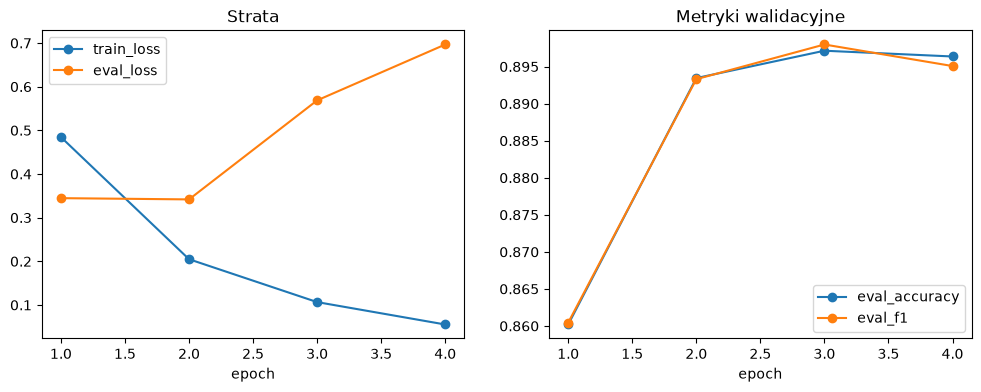

In [6]:
import matplotlib.pyplot as plt

history = result["history"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history.plot(x="epoch", y=["train_loss", "eval_loss"], marker="o", ax=axes[0], title="Strata")
history.plot(x="epoch", y=["eval_accuracy", "eval_f1"], marker="o", ax=axes[1], title="Metryki walidacyjne")
plt.show()

## 5. Ewaluacja na zbiorze testowym (etap `evaluate`)

🏃 View run defiant-tern-999 at: https://dagshub.com/irintinuviel/crypto_sentiment.mlflow/#/experiments/0/runs/09c040aaf0c341c5acf4c558d2ac818c
🧪 View experiment at: https://dagshub.com/irintinuviel/crypto_sentiment.mlflow/#/experiments/0
              precision    recall  f1-score   support

    negative     0.9257    0.9355    0.9306      2172
     neutral     0.8078    0.8588    0.8325      1424
    positive     0.9436    0.8747    0.9078      1548

    accuracy                         0.8960      5144
   macro avg     0.8924    0.8897    0.8903      5144
weighted avg     0.8985    0.8960    0.8966      5144



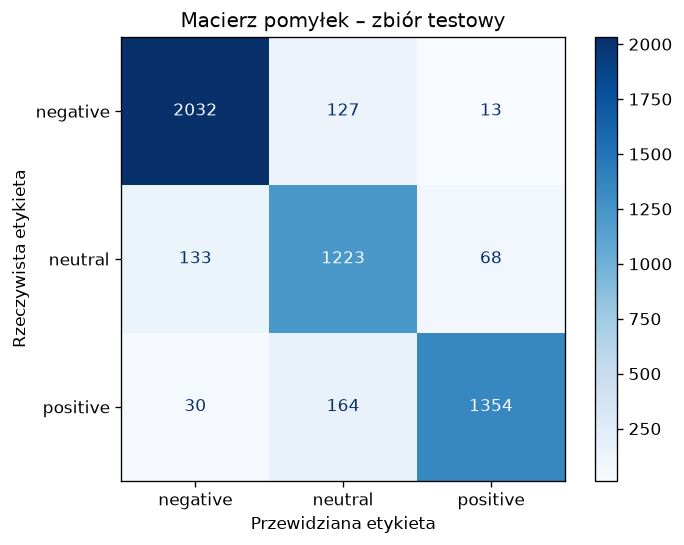

{'accuracy': 0.896,
 'f1_weighted': 0.8966,
 'f1_macro': 0.8903,
 'f1_negative': 0.9306,
 'f1_neutral': 0.8325,
 'f1_positive': 0.9078}

In [7]:
from IPython.display import Image, display

from src.evaluate import evaluate

metrics = evaluate(params)
display(Image("reports/confusion_matrix.png"))
metrics

In [8]:
import pandas as pd

# błędnie sklasyfikowane przykłady
pd.read_csv("reports/misclassified.csv").head(10)

,text,actual,predicted
0,"a week after this tweet, zhao tweeted that bin...",negative,neutral
1,seems like trump is more bullish for solana...,positive,neutral
2,"doesn't need to work anymore, ever, with that ...",neutral,negative
3,how? if 1000 people sell $1 worth of btc and 1...,neutral,negative
4,tomorrow’s headline: “bitcoin plummets to belo...,negative,neutral
5,i hope he stuck to his second sentence and act...,positive,neutral
6,"it wasn’t a lot but it was 1.02 btc, which is ...",neutral,positive
7,funny thing about bitcoin is that it’s still r...,positive,neutral
8,this graph is clearly old because last i check...,negative,neutral
9,"yeah, should have seen the red flags after wha...",negative,neutral


## 6. Rejestracja modelu w MLflow Model Registry (opcjonalnie)

Rejestruje model jako `cryptobert-sentiment` z aliasem `champion` (w Jenkinsie robi to potok po progu jakości).

In [ ]:
REGISTER = False

if REGISTER:
    from src.register import register

    register()

## 7. Predykcja – tak samo jak w API

In [ ]:
from src.predict import Predictor

predictor = Predictor("models/model", max_length=params["train"]["max_length"])
predictor.predict([
    "bitcoin is going to the moon, best investment ever",
    "eth gas fees are killing me, this is a scam",
    "just bought some btc today",
])